# TP1 — Detecção de Anomalias Visuais (BCC406 · DECOM/UFOP)

| | |
|---|---|
| **Aluno** | Ana Paula Tadim e Otávio Alves |
| **Nível** | Graduação |
| **Dataset** | VisA (12 categorias) |
| **Método** | STFPM — destilação professor-aluno (ResNet-18), com data augmentation e hiperparâmetros (σ, regra, augmentation) escolhidos por **validação sintética** (CutPaste) |
| **Escore da competição** | **S_grad = 93,96 %** (AUROC de imagem médio nas 12 categorias do VisA) |
| **Baseline do kit** | 77,3 % (AUROC de imagem, VisA) |
| **Bônus de localização** | AUROC de pixel = 98,61 % · AU-PRO@30% = 91,34 % |

**Roteiro do notebook**

1. Configuração e ambiente
2. Carregamento dos dados (só normais no treino) e cache em memória
3. Exploração dos dados
4. Baseline do kit (ResNet-18 congelada + média por posição), reexecutado aqui para entrar na mesma tabela
5. Método: STFPM (arquitetura, perda e justificativa)
6. Treino one-class por categoria + inferência + avaliação oficial
7. Curvas de perda
8. Resultados: comparação com o baseline, ablações e regra de pontuação
9. Arquivo de submissão
10. Análise qualitativa (acertos e falhas) e mapas de anomalia (bônus)
11. Discussão e conclusão


## 1. Configuração

Todos os hiperparâmetros ficam nesta célula. Eles foram fixados **antes** de olhar o teste: são os valores do artigo do STFPM (Wang et al., 2021), e a época final é escolhida pela perda na validação (que só tem imagens normais), como manda a regra R1.

`CATS_RODAR` permite treinar e avaliar **só algumas categorias** para testes rápidos (p. ex. `CATS_RODAR = ["pcb1"]` leva ~5 min numa T4). Para a entrega oficial use `CATS_RODAR = None` (todas as 12): o CSV de submissão só é gerado com as 12 categorias, e o S_grad impresso em modo parcial é apenas indicativo.

`RETREINAR = False` faz o notebook carregar os alunos já treinados que estiverem salvos no Drive. Assim, se o Colab desconectar, ele continua de onde parou. Para refazer tudo do zero, use `True`.

In [1]:
NOME_ARQUIVO = "otavio-alves"  # gera otavio-alves.csv (formato nome-sobrenome)
SEMENTE      = 42
TAM          = 256             # resolução de entrada (a avaliação oficial é 256x256)
EPOCAS       = 100             # STFPM original: 100 épocas
BATCH        = 32
LR           = 0.4             # SGD, como no artigo do STFPM
MOMENTUM     = 0.9
WEIGHT_DECAY = 1e-4
SIGMA_SUAV   = 4               # σ padrão; o σ OFICIAL é escolhido na Seção 6.2
SIGMAS_PROXY = [2, 4, 8]       # grade de σ avaliada na validação sintética
RETREINAR    = False           # True = ignora checkpoints salvos e treina de novo
FAZER_ABLACAO = True           # avalia também o aluno SEM treino (pesos aleatórios)

# Teste rápido: liste as categorias a rodar, ex. ["pcb1"] ou ["pcb1", "candle"].
# None = todas as 12 (obrigatório para gerar o CSV de submissão).
CATS_RODAR   = None

In [2]:
# ---- Ambiente e dados -------------------------------------------------------
# Estrutura no Drive:
#   MyDrive/TP1_BCC406/datasets/visa.zip
#   MyDrive/TP1_BCC406/kit_apoio/tp1_utils.py
# O .zip é copiado para o disco LOCAL do Colab e descompactado lá (ler direto
# do Drive é muito lento).
import os, sys, glob, shutil, subprocess, time, copy, json

EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PASTA_DRIVE = "/content/drive/MyDrive/TP1_BCC406"   # <- ajuste se necessário
    DESTINO = "/content/dados"
    SAIDA = PASTA_DRIVE                                  # CSV, figuras e checkpoints
    os.makedirs(DESTINO, exist_ok=True)
    if not glob.glob(os.path.join(DESTINO, "**", "split.csv"), recursive=True):
        zip_drive = os.path.join(PASTA_DRIVE, "datasets", "visa.zip")
        zip_local = os.path.join(DESTINO, "visa.zip")
        print("copiando o zip para o disco local..."); t0 = time.time()
        shutil.copy(zip_drive, zip_local)
        print("descompactando...")
        subprocess.run(["unzip", "-q", "-o", zip_local, "-d", DESTINO], check=True)
        os.remove(zip_local)
        print(f"pronto em {time.time() - t0:.0f}s")
    shutil.copy(os.path.join(PASTA_DRIVE, "kit", "tp1_utils.py"), DESTINO)
    sys.path.insert(0, DESTINO)
else:
    DESTINO = os.environ.get("TP1_RAIZ", "content")
    SAIDA = "."
    for _p in ("kit_apoio", "kit"):                 # pasta local com tp1_utils.py
        if os.path.exists(os.path.join(_p, "tp1_utils.py")):
            sys.path.insert(0, _p)
    sys.path.insert(0, DESTINO)

# RAIZ = pasta que contém visa/split.csv (funciona com ou sem a pasta "visa" no zip)
achados = sorted(glob.glob(os.path.join(DESTINO, "**", "split.csv"), recursive=True), key=len)
assert achados, f"split.csv não encontrado em {DESTINO}"
pasta_visa = os.path.dirname(achados[0])
if os.path.basename(pasta_visa) == "visa":
    RAIZ = os.path.dirname(pasta_visa)
else:                                    # zip sem a pasta "visa": cria um link
    RAIZ = DESTINO.rstrip("/") + "_raiz"
    os.makedirs(RAIZ, exist_ok=True)
    if not os.path.exists(os.path.join(RAIZ, "visa")):
        os.symlink(os.path.abspath(pasta_visa), os.path.join(RAIZ, "visa"))

import tp1_utils as U
CATS = U.CATEGORIAS["visa"]
if CATS_RODAR:                                       # subconjunto p/ testes rápidos
    invalidas = [c for c in CATS_RODAR if c not in CATS]
    assert not invalidas, f"categorias inválidas: {invalidas}"
    CATS = [c for c in CATS if c in CATS_RODAR]
COMPLETO = len(CATS) == len(U.CATEGORIAS["visa"])
if not COMPLETO:
    print(f"ATENÇÃO: modo de teste com {len(CATS)} categoria(s): {CATS}.")
    print("A submissão oficial exige as 12 — use CATS_RODAR = None para a entrega.")
DIR_CKPT = os.path.join(SAIDA, "modelos_stfpm"); os.makedirs(DIR_CKPT, exist_ok=True)
DIR_CACHE = "/content/cache" if EM_COLAB else "cache"; os.makedirs(DIR_CACHE, exist_ok=True)
print("RAIZ =", RAIZ)
print("categorias:", CATS)

Mounted at /content/drive
copiando o zip para o disco local...
descompactando...
pronto em 63s
RAIZ = /content/dados
categorias: ['candle', 'capsules', 'cashew', 'chewinggum', 'fryum', 'macaroni1', 'macaroni2', 'pcb1', 'pcb2', 'pcb3', 'pcb4', 'pipe_fryum']


In [3]:
import math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

DEV = "cuda" if torch.cuda.is_available() else "cpu"
USAR_AMP = DEV == "cuda"             # precisão mista (fp16) na GPU
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
U.fixar_semente(SEMENTE)
print("dispositivo:", DEV, "|", torch.cuda.get_device_name(0) if DEV == "cuda" else "")
print("torch", torch.__version__, "| torchvision", torchvision.__version__)

dispositivo: cuda | Tesla T4
torch 2.14.1+cu130 | torchvision 0.29.1+cu130


## 2. Carregamento dos dados

Os splits vêm de `U.listar_amostras`, a divisão oficial do kit:

* `train`: só imagens normais, usadas para **treinar** o aluno;
* `val`: só imagens normais (10% do treino, sorteadas pelo kit), usadas para escolher a época (menor perda) e para calcular um limiar **apenas para a análise qualitativa**;
* `test`: imagens normais e anômalas, usadas **uma única vez**, na avaliação final. O teste nunca entra no treino nem na escolha de nada.

Decodificar JPEGs de ~1500×1000 a cada época é lento. Por isso, cada split é lido **uma vez**, redimensionado para 256×256 com a mesma transformação do kit (`Resize` bilinear) e guardado como tensor `uint8` em disco local. A normalização do ImageNet é feita na GPU, e o resultado é idêntico ao de `U.transformacao_padrao(256)`.

In [4]:
_redim = T.Resize((TAM, TAM), interpolation=T.InterpolationMode.BILINEAR)
MEAN = torch.tensor(U.IMAGENET_MEAN, device=DEV).view(1, 3, 1, 1)
STD  = torch.tensor(U.IMAGENET_STD,  device=DEV).view(1, 3, 1, 1)


def _ler(caminho):
    return np.asarray(_redim(Image.open(caminho).convert("RGB")), dtype=np.uint8)


def carregar_split(cat, split):
    # Retorna {'X': uint8 (N,3,TAM,TAM), 'y': (N,), 'paths', ['M': (N,256,256) só no teste]}
    arq = os.path.join(DIR_CACHE, f"{cat}_{split}_{TAM}.pt")
    if os.path.exists(arq):
        return torch.load(arq, weights_only=False)
    am = U.listar_amostras(RAIZ, "visa", cat, split)
    with ThreadPoolExecutor(8) as ex:
        imgs = list(ex.map(_ler, [a.imagem for a in am]))
    d = {"X": torch.from_numpy(np.stack(imgs)).permute(0, 3, 1, 2).contiguous(),
         "y": torch.tensor([a.rotulo for a in am]),
         "paths": [a.imagem for a in am]}
    if split == "test":   # máscaras na resolução OFICIAL (256x256, vizinho mais próximo)
        d["M"] = torch.from_numpy(np.stack([U.carregar_mascara(a.mascara) for a in am]))
    torch.save(d, arq)
    return d


def preparar(xb):
    # uint8 (B,3,H,W) -> float normalizado (ImageNet) na GPU
    return (xb.to(DEV, non_blocking=True).float() / 255.0 - MEAN) / STD


t0 = time.time()
for cat in CATS:
    for sp in ["train", "val", "test"]:
        carregar_split(cat, sp)
    print(f"{cat:12s} em cache ({time.time() - t0:.0f}s)")

candle       em cache (17s)
capsules     em cache (28s)
cashew       em cache (38s)
chewinggum   em cache (48s)
fryum        em cache (57s)
macaroni1    em cache (74s)
macaroni2    em cache (90s)
pcb1         em cache (108s)
pcb2         em cache (125s)
pcb3         em cache (142s)
pcb4         em cache (160s)
pipe_fryum   em cache (169s)


## 3. Exploração dos dados

O VisA tem três grupos com dificuldades bem diferentes:

* **PCBs** (`pcb1`–`pcb4`): estrutura complexa, com muitos componentes pequenos;
* **múltiplas instâncias** (`candle`, `capsules`, `macaroni1/2`): várias peças por imagem, e a posição de cada uma varia;
* **objeto único** (`cashew`, `chewinggum`, `fryum`, `pipe_fryum`): pose e textura variam de imagem para imagem.

In [5]:
linhas = []
for cat in CATS:
    te = U.listar_amostras(RAIZ, "visa", cat, "test")
    w, h = Image.open(te[0].imagem).size
    linhas.append({"categoria": cat,
                   "treino": len(U.listar_amostras(RAIZ, "visa", cat, "train")),
                   "val": len(U.listar_amostras(RAIZ, "visa", cat, "val")),
                   "teste normal": sum(a.rotulo == 0 for a in te),
                   "teste anômala": sum(a.rotulo == 1 for a in te),
                   "resolução": f"{w}x{h}"})
tab_dados = pd.DataFrame(linhas)
display(tab_dados)
print("total:", tab_dados[["treino", "val", "teste normal", "teste anômala"]].sum().to_dict())

,categoria,treino,val,teste normal,teste anômala,resolução
0,candle,810,90,100,100,1284x1168
1,capsules,488,54,60,100,1500x1000
2,cashew,405,45,50,100,1274x1176
3,chewinggum,408,45,50,100,1342x1118
4,fryum,405,45,50,100,1500x1000
5,macaroni1,810,90,100,100,1500x1000
6,macaroni2,810,90,100,100,1500x1000
7,pcb1,814,90,100,100,1404x1070
8,pcb2,811,90,100,100,1404x1070
9,pcb3,815,90,101,100,1562x960


total: {'treino': 7795, 'val': 864, 'teste normal': 962, 'teste anômala': 1200}


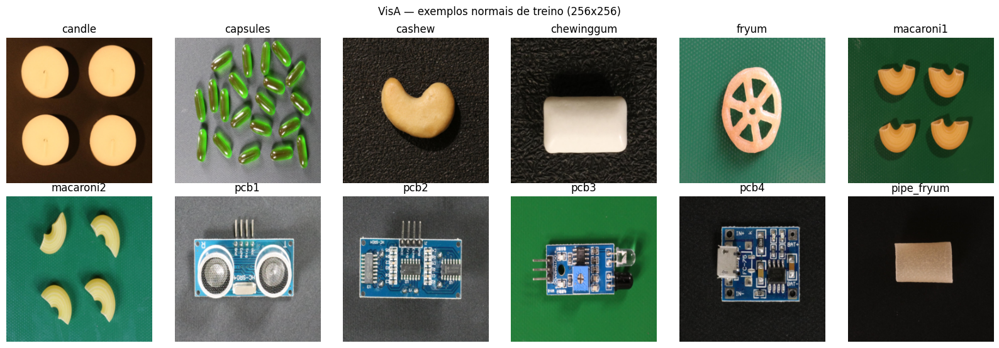

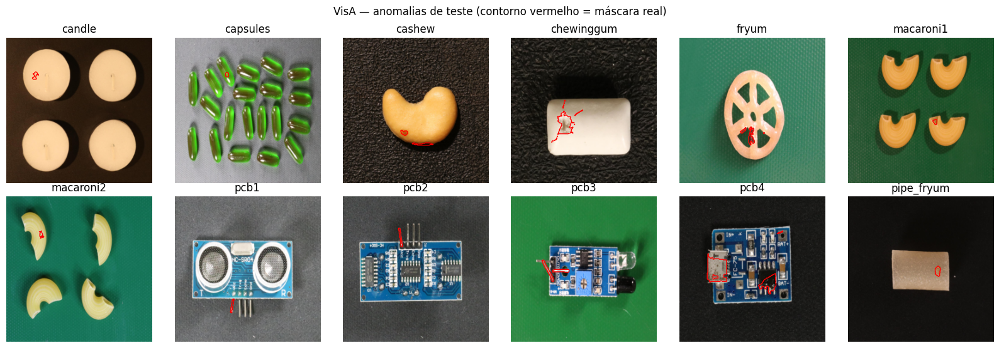

Mediana da área do defeito (% da imagem) por categoria:
candle        0.15
capsules      0.15
cashew        0.14
chewinggum    0.50
fryum         0.21
macaroni1     0.05
macaroni2     0.05
pcb1          0.20
pcb2          0.26
pcb3          0.24
pcb4          0.87
pipe_fryum    0.15


In [6]:
NCOL = min(6, len(CATS)); NROW = math.ceil(len(CATS) / NCOL)

# Uma imagem normal de treino por categoria
fig, ax = plt.subplots(NROW, NCOL, figsize=(2.7 * NCOL, 2.8 * NROW), squeeze=False)
for a, cat in zip(ax.ravel(), CATS):
    a.imshow(carregar_split(cat, "train")["X"][0].permute(1, 2, 0).numpy())
    a.set_title(cat)
for a in ax.ravel(): a.axis("off")
plt.suptitle("VisA — exemplos normais de treino (256x256)"); plt.tight_layout(); plt.show()

# Uma anômala de teste por categoria, com o contorno da máscara e a fração de área defeituosa
fig, ax = plt.subplots(NROW, NCOL, figsize=(2.7 * NCOL, 2.8 * NROW), squeeze=False)
areas = {}
for a, cat in zip(ax.ravel(), CATS):
    te = carregar_split(cat, "test")
    idx = torch.nonzero(te["y"] == 1)[0].item()
    a.imshow(te["X"][idx].permute(1, 2, 0).numpy())
    a.contour(te["M"][idx].numpy(), levels=[0.5], colors="red", linewidths=1)
    a.set_title(cat)
    m_anom = te["M"][te["y"] == 1].float()
    areas[cat] = 100 * m_anom.mean(dim=(1, 2)).median().item()
for a in ax.ravel(): a.axis("off")
plt.suptitle("VisA — anomalias de teste (contorno vermelho = máscara real)"); plt.tight_layout(); plt.show()

print("Mediana da área do defeito (% da imagem) por categoria:")
print(pd.Series(areas).round(2).to_string())


**Observações.** A mediana da área do defeito é minúscula: **≤ 0,26% da imagem em 10 das 12 categorias** (mínimo de 0,05% em `macaroni1`/`macaroni2`; máximos de 0,50% em `chewinggum` e 0,87% em `pcb4`). Em 256×256 isso significa poucas dezenas de pixels — uma ou duas posições nos mapas de features — e é o principal limite de qualquer método nessa resolução. Nas categorias de múltiplas instâncias (`candle`, `capsules`, `macaroni1/2`), a posição das peças muda entre imagens normais, o que tende a confundir um modelo "por posição" como o baseline — e de fato é onde ele mais sofre (Seção 8.1: `capsules` 55,6% e `macaroni2` 54,6% de AUROC de imagem, perto do acaso).


## 4. Baseline do kit (sem treino)

É o mesmo código de `exemplo_baseline.ipynb`: ResNet-18 congelada, com features de `layer2`+`layer3` (384 canais em 32×32). O mapa é a distância quadrática de cada patch à **média das features normais naquela posição**, e o escore é o máximo do mapa. Ele roda aqui para que baseline e modelo fiquem **na mesma tabela e com os mesmos dados**.

In [7]:
class ExtratorBaseline(nn.Module):
    # Idêntico ao do kit: layer2 + layer3 (reamostrada) + avg_pool 3x3 -> (B,384,32,32)
    def __init__(self):
        super().__init__()
        r = torchvision.models.resnet18(weights="IMAGENET1K_V1")
        self.base = nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool, r.layer1)
        self.layer2, self.layer3 = r.layer2, r.layer3

    def forward(self, x):
        f2 = self.layer2(self.base(x))
        f3 = F.interpolate(self.layer3(f2), size=f2.shape[-2:], mode="bilinear", align_corners=False)
        return F.avg_pool2d(torch.cat([f2, f3], 1), 3, 1, 1)


extrator_base = ExtratorBaseline().to(DEV).eval()


@torch.no_grad()
def rodar_baseline(tr, te):
    soma, n = 0.0, 0
    for i in range(0, len(tr["X"]), BATCH):
        f = extrator_base(preparar(tr["X"][i:i + BATCH]))
        soma = soma + f.sum(0); n += f.shape[0]
    mu = soma / n
    esc, mapas = [], []
    for i in range(0, len(te["X"]), BATCH):
        f = extrator_base(preparar(te["X"][i:i + BATCH]))
        m = ((f - mu[None]) ** 2).sum(1)
        mapas.append(U.mapa_para_eval(m.cpu()))
        esc.append(m.flatten(1).amax(1).cpu().numpy())
    return np.concatenate(esc), np.concatenate(mapas)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 143MB/s]


## 5. Método: STFPM (Student-Teacher Feature Pyramid Matching)

**Referência:** G. Wang, S. Han, E. Ding, D. Huang. *Student-Teacher Feature Pyramid Matching for Anomaly Detection.* BMVC 2021 (ref. [9] do enunciado). O código abaixo foi escrito por mim a partir da descrição do artigo, sem bibliotecas de detecção prontas.

**Ideia.** Uma **professora** $T$ (ResNet-18 pré-treinada no ImageNet, **congelada**) e uma **aluna** $S$ com a mesma arquitetura, mas com **pesos aleatórios**, treinada por retropropagação **só com imagens normais** para reproduzir as features da professora em três escalas (`layer1` 64×64, `layer2` 32×32, `layer3` 16×16). Nas regiões normais, a aluna aprende a imitar a professora. Em um defeito, que ela nunca viu, a imitação falha, e essa **discrepância** é o mapa de anomalia.

**Perda** (para cada escala $l$, com features normalizadas por L2 ao longo dos canais, $\hat F = F/\lVert F \rVert_2$):

$$\mathcal{L} = \sum_{l=1}^{3} \frac{1}{h_l w_l} \sum_{i,j} \tfrac12 \big\lVert \hat F^T_l(i,j) - \hat F^S_l(i,j) \big\rVert_2^2$$

**Regra de pontuação:** o mapa de cada escala é $\tfrac12\lVert \hat F^T - \hat F^S \rVert^2$ por posição, ampliado para 256×256. As escalas são combinadas (produto, como no artigo, ou alternativas), o mapa é suavizado com uma gaussiana e o escore $s(x)$ é derivado do mapa (máximo ou média do top-1%). A combinação de escalas, o σ e o uso de **data augmentation** (flips aleatórios no treino, aplicados igualmente à professora e à aluna) são **escolhidos na Seção 6.2 pela validação sintética** — ou seja, sem nunca tocar no teste.

**Por que esse método (e não um autoencoder)?**
* Autoencoders convolucionais de pixels costumam **generalizar demais**: reconstroem até o defeito, e o erro fica alto em bordas e texturas normais. O próprio enunciado alerta para isso.
* Comparar features de uma rede pré-treinada é mais robusto a variações pequenas de iluminação e textura do que comparar pixels.
* A aluna **é treinada do zero**, o que cumpre a regra do "componente treinado por você". O mesmo processo já produz o **mapa** $A(x)$, que serve para o bônus de localização.
* Só usa CNNs (ResNet-18), e os pesos pré-treinados vêm só do ImageNet, ambos permitidos.

**Protocolo.** Um modelo por categoria (regra R4), com 100 épocas e SGD (lr 0,4, momentum 0,9, weight decay 1e-4), como no artigo. A cada época, a perda é medida na validação (só normais), e o modelo final é o da **época com menor perda de validação**. Cada categoria tem **duas variantes** treinadas — sem e com augmentation (flips aleatórios) — e a variante usada no teste é a de maior AUROC-proxy na validação sintética (Seção 6.2).

In [8]:
class PiramideResNet18(nn.Module):
    # ResNet-18 até layer3, devolve [layer1 (64x64), layer2 (32x32), layer3 (16x16)]
    def __init__(self, pretreinada):
        super().__init__()
        r = torchvision.models.resnet18(weights="IMAGENET1K_V1" if pretreinada else None)
        self.stem = nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool)
        self.l1, self.l2, self.l3 = r.layer1, r.layer2, r.layer3

    def forward(self, x):
        f1 = self.l1(self.stem(x)); f2 = self.l2(f1); f3 = self.l3(f2)
        return [f1, f2, f3]


professora = PiramideResNet18(pretreinada=True).to(DEV).eval()
for p in professora.parameters():
    p.requires_grad_(False)


def mapas_discrepancia(ft, fs):
    # Lista de mapas (B,h,w): 0.5 * ||norm(T) - norm(S)||^2 em cada posição
    return [0.5 * (F.normalize(t.float(), dim=1) - F.normalize(s.float(), dim=1)).pow(2).sum(1)
            for t, s in zip(ft, fs)]


def perda_stfpm(ft, fs):
    return sum(m.mean() for m in mapas_discrepancia(ft, fs))


def autocast():
    return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USAR_AMP)


aluno_tmp = PiramideResNet18(pretreinada=False)
N_PARAMS = sum(p.numel() for p in aluno_tmp.parameters())
print(f"parâmetros treináveis da aluna: {N_PARAMS / 1e6:.2f} M (professora congelada: mesmo tamanho)")
del aluno_tmp

parâmetros treináveis da aluna: 2.78 M (professora congelada: mesmo tamanho)


In [9]:
@torch.no_grad()
def perda_media(aluno, X):
    aluno.eval(); tot = 0.0
    for i in range(0, len(X), BATCH):
        x = preparar(X[i:i + BATCH])
        with autocast():
            ft, fs = professora(x), aluno(x)
        tot += perda_stfpm(ft, fs).item() * len(x)
    return tot / len(X)


def treinar_aluno(X_tr, X_va, augmentar=False):
    U.fixar_semente(SEMENTE)
    aluno = PiramideResNet18(pretreinada=False).to(DEV)
    opt = torch.optim.SGD(aluno.parameters(), lr=LR, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
    scaler = torch.amp.GradScaler("cuda", enabled=USAR_AMP)
    X_gpu = X_tr.to(DEV)                      # uint8 na GPU (~160 MB no máximo)
    n = len(X_gpu)
    hist = {"treino": [], "val": []}
    melhor = (float("inf"), None, -1)
    t0 = time.time()
    for ep in range(EPOCAS):
        aluno.train()
        perm = torch.randperm(n, device=DEV)
        soma, cont = 0.0, 0
        for i in range(0, n - BATCH + 1, BATCH):          # drop_last
            xb = X_gpu[perm[i:i + BATCH]]                 # indexação avançada = cópia
            if augmentar:                                  # flips aleatórios por imagem
                fh = torch.rand(len(xb), device=DEV) < 0.5
                fv = torch.rand(len(xb), device=DEV) < 0.5
                xb[fh] = xb[fh].flip(-1)
                xb[fv] = xb[fv].flip(-2)
            x = preparar(xb)
            with autocast():
                with torch.no_grad():
                    ft = professora(x)
                fs = aluno(x)
            loss = perda_stfpm(ft, fs)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            soma += loss.item() * len(x); cont += len(x)
        hist["treino"].append(soma / cont)
        v = perda_media(aluno, X_va)
        hist["val"].append(v)
        if v < melhor[0]:
            melhor = (v, copy.deepcopy(aluno.state_dict()), ep)
        if ep % 10 == 0 or ep == EPOCAS - 1:
            print(f"   época {ep:3d}  perda treino {hist['treino'][-1]:.4f}  val {v:.4f}  ({time.time() - t0:.0f}s)")
    aluno.load_state_dict(melhor[1])
    return aluno, hist, melhor[2], time.time() - t0

In [10]:
@torch.no_grad()
def inferir_camadas(aluno, X):
    # Mapas por escala, ampliados para 256x256: (N, 3, 256, 256) na CPU
    aluno.eval(); saida = []
    for i in range(0, len(X), BATCH):
        x = preparar(X[i:i + BATCH])
        with autocast():
            ft, fs = professora(x), aluno(x)
        ms = [F.interpolate(m[:, None], size=(U.EVAL_SIZE, U.EVAL_SIZE), mode="bilinear",
                            align_corners=False)[:, 0] for m in mapas_discrepancia(ft, fs)]
        saida.append(torch.stack(ms, 1).float().cpu())
    return torch.cat(saida)


@torch.no_grad()
def suavizar(m, sigma=SIGMA_SUAV):
    # Suavização gaussiana de mapas (N,H,W), feita na GPU em blocos
    k = 2 * int(4 * sigma + 0.5) + 1
    out = []
    for i in range(0, len(m), 64):
        b = m[i:i + 64, None].to(DEV)
        out.append(TF.gaussian_blur(b, kernel_size=k, sigma=sigma)[:, 0].cpu())
    return torch.cat(out)


# ---- Regras de pontuação: mapas por escala (N,3,256,256) -> (mapa (N,256,256), escore (N,))
def regra_produto_max(P, stats=None, sigma=SIGMA_SUAV):
    # REGRA OFICIAL (fixada a priori): produto das escalas (artigo) + gaussiana + máximo
    m = suavizar(P.prod(1), sigma)
    return m, m.flatten(1).amax(1)


def regra_soma_norm_max(P, stats, sigma=SIGMA_SUAV):
    # Alternativa: cada escala padronizada com média/desvio da VALIDAÇÃO, depois soma
    mu, sd = stats
    m = suavizar(((P - mu.view(1, 3, 1, 1)) / sd.view(1, 3, 1, 1)).sum(1), sigma)
    return m, m.flatten(1).amax(1)


def regra_produto_top1(P, stats=None, sigma=SIGMA_SUAV):
    # Alternativa: mesmo mapa da oficial, mas escore = média do 1% de pixels mais altos
    m = suavizar(P.prod(1), sigma)
    k = max(1, int(0.01 * m[0].numel()))
    return m, m.flatten(1).topk(k, dim=1).values.mean(1)


REGRAS = {"produto+max (oficial)": regra_produto_max,
          "soma normalizada+max": regra_soma_norm_max,
          "produto+top1%": regra_produto_top1}

### 5.1 Anomalias sintéticas de validação (CutPaste)

A regra R1 permite escolher hiperparâmetros usando apenas as imagens normais de `train`/`val`, e a R3 incentiva anomalias **sintéticas**. Como o `val` só tem normais, não dá para medir AUROC nele diretamente — a dica do próprio enunciado é criar **anomalias sintéticas de validação**.

Para cada imagem de validação, uma cópia é danificada no estilo **CutPaste** (Li et al., CVPR 2021): um retângulo da própria imagem (0,5%–3% da área, proporção variada) é recortado e colado em outra posição. O conjunto {val normal = 0, val danificada = 1} dá um **AUROC-proxy**, usado na Seção 6.2 para escolher augmentation, σ e regra de pontuação **antes** de qualquer contato com o teste. **Essas imagens danificadas nunca entram no treino** — servem só para avaliar.


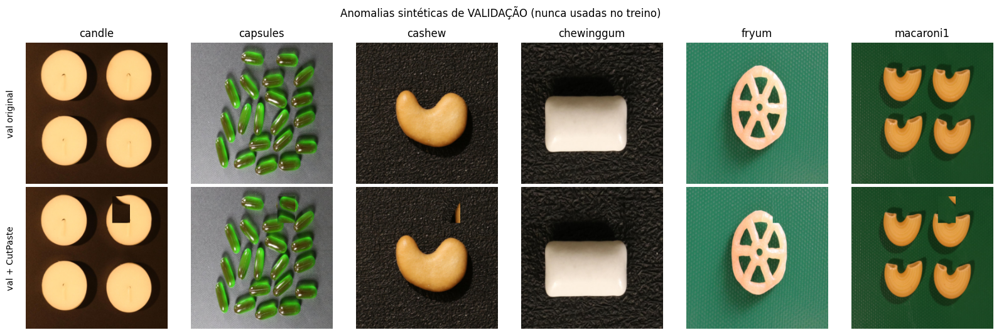

In [11]:
def aplicar_cutpaste(X, semente=SEMENTE):
    # X: uint8 (N,3,H,W) -> cópia com um retângulo da própria imagem colado em
    # outra posição (defeito sintético estilo CutPaste). Determinística.
    rng = np.random.default_rng(semente)
    Xd = X.clone()
    N, _, H, W = X.shape
    for i in range(N):
        area = rng.uniform(0.005, 0.03) * H * W
        asp = rng.uniform(0.3, 3.0)
        ph = int(np.clip(np.sqrt(area * asp), 4, H // 2))
        pw = int(np.clip(np.sqrt(area / asp), 4, W // 2))
        ys, xs = int(rng.integers(0, H - ph)), int(rng.integers(0, W - pw))
        yd, xd = ys, xs
        for _ in range(10):                               # destino longe da origem
            yd, xd = int(rng.integers(0, H - ph)), int(rng.integers(0, W - pw))
            if abs(yd - ys) + abs(xd - xs) > (ph + pw) // 2:
                break
        patch = X[i, :, ys:ys + ph, xs:xs + pw]
        if rng.random() < 0.5:
            patch = patch.flip(-1)
        Xd[i, :, yd:yd + ph, xd:xd + pw] = patch
    return Xd


# Exemplos: validação original (linha 1) e danificada (linha 2)
cats_demo = CATS[:min(6, len(CATS))]
fig, ax = plt.subplots(2, len(cats_demo), figsize=(2.7 * len(cats_demo), 5.4), squeeze=False)
for j, cat in enumerate(cats_demo):
    va = carregar_split(cat, "val")
    dan = aplicar_cutpaste(va["X"][:1])
    ax[0, j].imshow(va["X"][0].permute(1, 2, 0).numpy()); ax[0, j].set_title(cat)
    ax[1, j].imshow(dan[0].permute(1, 2, 0).numpy())
for a in ax.ravel(): a.axis("off")
ax[0, 0].text(-20, 128, "val original", rotation=90, va="center", ha="right")
ax[1, 0].text(-20, 128, "val + CutPaste", rotation=90, va="center", ha="right")
plt.suptitle("Anomalias sintéticas de VALIDAÇÃO (nunca usadas no treino)")
plt.tight_layout(); plt.show()


## 6. Treino, seleção por validação sintética e avaliação final

O fluxo respeita a ordem do protocolo one-class:

1. **(6.1)** treinar, para cada categoria em `CATS`, **duas** alunas — sem e com data augmentation — usando só as normais de `train`, com a época escolhida pela perda na `val`;
2. **(6.2)** escolher **augmentation, σ e regra de pontuação** pela maior AUROC-proxy na validação sintética (Seção 5.1) — **sem tocar no teste**;
3. **(6.3)** só então rodar o teste, **uma única vez**, com a configuração escolhida, e avaliar com `U.avaliar_categoria` (avaliação oficial, sem alterações).

Tempo estimado numa T4: ~4–6 min por categoria **por variante**. Checkpoints em `TP1_BCC406/modelos_stfpm/` (`<cat>_s42.pt` sem augmentation, `<cat>_s42_aug.pt` com); os já salvos são reaproveitados.

### 6.1 Treino das alunas (sem teste)


In [12]:
alunos, historicos, custos_treino = {}, {}, {}        # chave: (cat, aug)

for cat in CATS:
    for aug in (False, True):
        tag = f"{cat}{'_aug' if aug else ''}"
        ckpt = os.path.join(DIR_CKPT, f"{cat}_s{SEMENTE}{'_aug' if aug else ''}.pt")
        if os.path.exists(ckpt) and not RETREINAR:
            c = torch.load(ckpt, map_location=DEV, weights_only=False)
            aluno = PiramideResNet18(pretreinada=False).to(DEV)
            aluno.load_state_dict(c["estado"])
            hist, ep_melhor, t_treino = c["hist"], c["ep_melhor"], c["t_treino"]
            print(f"{tag:22s} checkpoint carregado (melhor época {ep_melhor})")
        else:
            print(f"\n=== treinando {tag} ===")
            tr, va = carregar_split(cat, "train"), carregar_split(cat, "val")
            aluno, hist, ep_melhor, t_treino = treinar_aluno(tr["X"], va["X"], augmentar=aug)
            torch.save({"estado": aluno.state_dict(), "hist": hist, "ep_melhor": ep_melhor,
                        "t_treino": t_treino}, ckpt)
        alunos[(cat, aug)] = aluno.cpu()                  # guarda na CPU (24 alunas cabem)
        historicos[(cat, aug)] = (hist, ep_melhor)
        custos_treino[(cat, aug)] = t_treino
if DEV == "cuda": torch.cuda.empty_cache()


candle                 checkpoint carregado (melhor época 92)
candle_aug             checkpoint carregado (melhor época 98)
capsules               checkpoint carregado (melhor época 97)
capsules_aug           checkpoint carregado (melhor época 99)
cashew                 checkpoint carregado (melhor época 99)
cashew_aug             checkpoint carregado (melhor época 94)
chewinggum             checkpoint carregado (melhor época 93)
chewinggum_aug         checkpoint carregado (melhor época 87)
fryum                  checkpoint carregado (melhor época 99)
fryum_aug              checkpoint carregado (melhor época 96)
macaroni1              checkpoint carregado (melhor época 97)
macaroni1_aug          checkpoint carregado (melhor época 86)

=== treinando macaroni2 ===
   época   0  perda treino 0.9070  val 0.7662  (5s)
   época  10  perda treino 0.2077  val 0.2147  (24s)
   época  20  perda treino 0.1465  val 0.1477  (44s)
   época  30  perda treino 0.1188  val 0.1249  (65s)
   época  40  pe

### 6.2 Escolha de hiperparâmetros pela validação sintética

Para cada categoria e cada variante (sem/com augmentation), os mapas são calculados na validação **real** (rótulo 0) e na validação **danificada** com CutPaste (rótulo 1). Cada combinação (augmentation × regra × σ) recebe o **AUROC-proxy médio** entre as categorias, e a combinação vencedora vira a configuração **oficial** do teste. O teste não participa de nada aqui. As estatísticas da regra "soma normalizada" vêm da validação real (regra R1).

A escolha é **global** (uma configuração para todas as categorias), para manter a seleção simples e evitar sobreajuste ao proxy.


In [13]:
P_val, P_sin = {}, {}            # (cat, aug) -> mapas por escala na val real / danificada
for cat in CATS:
    va = carregar_split(cat, "val")
    X_dan = aplicar_cutpaste(va["X"])
    for aug in (False, True):
        aluno = alunos[(cat, aug)].to(DEV)
        P_val[(cat, aug)] = inferir_camadas(aluno, va["X"])
        P_sin[(cat, aug)] = inferir_camadas(aluno, X_dan)
        aluno.cpu()
    print(f"{cat:12s} proxy calculado")

linhas = []
for aug in (False, True):
    for nome, regra in REGRAS.items():
        for sg in SIGMAS_PROXY:
            vals = []
            for cat in CATS:
                Pv, Ps = P_val[(cat, aug)], P_sin[(cat, aug)]
                stats = (Pv.mean(dim=(0, 2, 3)), Pv.std(dim=(0, 2, 3)))
                _, e_n = regra(Pv, stats, sigma=sg)
                _, e_a = regra(Ps, stats, sigma=sg)
                y = np.r_[np.zeros(len(e_n)), np.ones(len(e_a))]
                vals.append(100 * U.auroc_imagem(y, np.r_[e_n.numpy(), e_a.numpy()]))
            linhas.append({"augmentation": aug, "regra": nome, "sigma": sg,
                           "proxy AUROC médio (%)": np.mean(vals)})
tab_proxy = pd.DataFrame(linhas).sort_values("proxy AUROC médio (%)", ascending=False,
                                             ignore_index=True)
display(tab_proxy.round(2).head(12))

melhor = tab_proxy.iloc[0]
AUG_OFICIAL        = bool(melhor["augmentation"])
REGRA_OFICIAL_NOME = str(melhor["regra"])
REGRA_OFICIAL      = REGRAS[REGRA_OFICIAL_NOME]
SIGMA_OFICIAL      = int(melhor["sigma"])
print(f"\nCONFIGURAÇÃO OFICIAL (maior proxy médio, escolhida SEM tocar no teste):")
print(f"  augmentation = {AUG_OFICIAL} | regra = '{REGRA_OFICIAL_NOME}' | sigma = {SIGMA_OFICIAL}"
      f"  (proxy {melhor['proxy AUROC médio (%)']:.2f}%)")

P_val = {k: v for k, v in P_val.items() if k[1] == AUG_OFICIAL}   # libera memória
del P_sin


candle       proxy calculado
capsules     proxy calculado
cashew       proxy calculado
chewinggum   proxy calculado
fryum        proxy calculado
macaroni1    proxy calculado
macaroni2    proxy calculado
pcb1         proxy calculado
pcb2         proxy calculado
pcb3         proxy calculado
pcb4         proxy calculado
pipe_fryum   proxy calculado


,augmentation,regra,sigma,proxy AUROC médio (%)
0,False,soma normalizada+max,8,93.64
1,False,soma normalizada+max,4,93.39
2,False,soma normalizada+max,2,93.13
3,False,produto+top1%,2,92.90
4,False,produto+top1%,4,92.82
5,False,produto+top1%,8,92.82
6,True,soma normalizada+max,8,92.69
7,False,produto+max (oficial),8,92.66
8,False,produto+max (oficial),4,92.53
9,False,produto+max (oficial),2,92.50



CONFIGURAÇÃO OFICIAL (maior proxy médio, escolhida SEM tocar no teste):
  augmentation = False | regra = 'soma normalizada+max' | sigma = 8  (proxy 93.64%)


### 6.3 Avaliação final no teste (uma única vez)

Com a configuração travada na Seção 6.2, o laço roda o baseline do kit e a aluna escolhida no **teste** e avalia com `U.avaliar_categoria`. Também guarda: o limiar do percentil 95 dos escores da **validação** (só para a análise qualitativa da Seção 10), a comparação pós-hoc das regras no teste (Seção 8.3) e a ablação da aluna **sem treino** (pesos aleatórios).


In [14]:
def tabela_resultados(res):
    # U.avaliar_dataset exige as 12 categorias; em modo de teste monta uma tabela parcial
    if COMPLETO:
        return U.avaliar_dataset(res, "visa")
    df = pd.DataFrame([{"dataset": "visa", "categoria": c, **res[c]} for c in CATS])
    media = {"dataset": "visa", "categoria": "MEDIA (parcial)",
             **df[["img_auroc", "px_auroc", "au_pro"]].mean().to_dict()}
    return pd.concat([df, pd.DataFrame([media])], ignore_index=True)


res_base, res_stfpm, res_sem_treino = {}, {}, {}
res_regras = {r: {} for r in REGRAS}
saidas, custos = {}, {}

for cat in CATS:
    print(f"\n=== {cat} ===")
    tr, te = carregar_split(cat, "train"), carregar_split(cat, "test")
    y_te, M_te = te["y"].numpy(), te["M"].numpy()

    # 1) baseline do kit
    esc_b, mapas_b = rodar_baseline(tr, te)
    res_base[cat] = U.avaliar_categoria(y_te, esc_b, M_te, mapas_b)

    # 2) aluna escolhida: inferência no teste (uma vez) com a configuração oficial
    aluno = alunos[(cat, AUG_OFICIAL)].to(DEV)
    Pv = P_val[(cat, AUG_OFICIAL)]
    stats_va = (Pv.mean(dim=(0, 2, 3)), Pv.std(dim=(0, 2, 3)))
    if DEV == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    P_te = inferir_camadas(aluno, te["X"])
    mapa_te, esc_te = REGRA_OFICIAL(P_te, stats_va, sigma=SIGMA_OFICIAL)
    if DEV == "cuda": torch.cuda.synchronize()
    t_inf = (time.time() - t0) / len(te["X"])
    aluno.cpu()

    res_stfpm[cat] = U.avaliar_categoria(y_te, esc_te.numpy(), M_te, U.mapa_para_eval(mapa_te))
    custos[cat] = {"treino (s)": custos_treino[(cat, AUG_OFICIAL)],
                   "inferência (ms/img)": 1000 * t_inf,
                   "melhor época": historicos[(cat, AUG_OFICIAL)][1]}

    # 3) limiar p/ análise qualitativa: percentil 95 dos escores da VALIDAÇÃO
    _, esc_va = REGRA_OFICIAL(Pv, stats_va, sigma=SIGMA_OFICIAL)

    # 4) regras de pontuação sobre as MESMAS features do teste (análise pós-hoc)
    for nome, regra in REGRAS.items():
        m, s = regra(P_te, stats_va, sigma=SIGMA_OFICIAL)
        res_regras[nome][cat] = U.avaliar_categoria(y_te, s.numpy(), M_te, U.mapa_para_eval(m))

    saidas[cat] = {"esc": esc_te.numpy(), "esc_base": esc_b, "mapa": mapa_te.half(), "y": y_te,
                   "limiar": float(np.percentile(esc_va.numpy(), 95))}

    # 5) ablação: aluna com pesos aleatórios (sem retropropagação)
    if FAZER_ABLACAO:
        U.fixar_semente(SEMENTE)
        aleat = PiramideResNet18(pretreinada=False).to(DEV)
        m0, s0 = REGRA_OFICIAL(inferir_camadas(aleat, te["X"]), stats_va, sigma=SIGMA_OFICIAL)
        res_sem_treino[cat] = U.avaliar_categoria(y_te, s0.numpy(), M_te, U.mapa_para_eval(m0))
        del aleat

    print(f"   baseline img {res_base[cat]['img_auroc']:.1f} | STFPM img {res_stfpm[cat]['img_auroc']:.1f}"
          f"  px {res_stfpm[cat]['px_auroc']:.1f}  pro {res_stfpm[cat]['au_pro']:.1f}")
    del P_te
    if DEV == "cuda": torch.cuda.empty_cache()

tab_base  = tabela_resultados(res_base)
tab_stfpm = tabela_resultados(res_stfpm)



=== candle ===
   baseline img 85.9 | STFPM img 91.0  px 98.9  pro 95.2

=== capsules ===
   baseline img 55.6 | STFPM img 83.8  px 98.5  pro 87.5

=== cashew ===
   baseline img 73.3 | STFPM img 96.0  px 98.3  pro 92.7

=== chewinggum ===
   baseline img 94.1 | STFPM img 99.1  px 98.5  pro 82.9

=== fryum ===
   baseline img 80.2 | STFPM img 95.9  px 95.5  pro 84.3

=== macaroni1 ===
   baseline img 75.1 | STFPM img 95.0  px 99.5  pro 96.6

=== macaroni2 ===
   baseline img 54.6 | STFPM img 87.4  px 99.2  pro 94.7

=== pcb1 ===
   baseline img 83.9 | STFPM img 94.2  px 99.7  pro 96.1

=== pcb2 ===
   baseline img 76.2 | STFPM img 94.2  px 98.6  pro 90.6

=== pcb3 ===
   baseline img 68.2 | STFPM img 92.9  px 98.9  pro 90.4

=== pcb4 ===
   baseline img 93.2 | STFPM img 99.0  px 98.7  pro 91.3

=== pipe_fryum ===
   baseline img 87.1 | STFPM img 99.1  px 99.1  pro 93.7


## 7. Evolução da perda

Perda de treino e de validação (só normais) por época, para a **variante escolhida** na Seção 6.2 (`AUG_OFICIAL`). A linha tracejada marca a época escolhida, a de menor perda de validação.

**Comentário.** Em todas as categorias a perda cai rapidamente nas ~10 primeiras épocas e depois segue diminuindo devagar; a perda de validação acompanha a de treino de perto, sem sinal de sobreajuste forte — apenas oscilações pontuais em algumas categorias (ex.: picos na validação de `candle` e `pipe_fryum`), que a escolha pela **menor perda de validação** neutraliza. As melhores épocas ficaram entre 86 e 99 (média 95,8), indicando que as 100 épocas do protocolo foram bem dimensionadas: mais épocas provavelmente ainda ajudariam um pouco, menos épocas cortariam o treino cedo.


## 8. Resultados

### 8.1 Comparação com o baseline (avaliação oficial)

In [16]:
comp = pd.DataFrame({
    "categoria": tab_stfpm["categoria"],
    "img AUROC baseline": tab_base["img_auroc"],
    "img AUROC STFPM": tab_stfpm["img_auroc"],
    "Δ img": tab_stfpm["img_auroc"] - tab_base["img_auroc"],
    "px AUROC baseline": tab_base["px_auroc"],
    "px AUROC STFPM": tab_stfpm["px_auroc"],
    "AU-PRO baseline": tab_base["au_pro"],
    "AU-PRO STFPM": tab_stfpm["au_pro"],
})
if FAZER_ABLACAO:
    comp.insert(2, "img AUROC aluna s/ treino", tabela_resultados(res_sem_treino)["img_auroc"])
display(comp.round(1).style.format(precision=1).background_gradient(subset=["Δ img"], cmap="RdYlGn"))

,categoria,img AUROC baseline,img AUROC aluna s/ treino,img AUROC STFPM,Δ img,px AUROC baseline,px AUROC STFPM,AU-PRO baseline,AU-PRO STFPM
0,candle,85.9,33.8,91.0,5.1,97.3,98.9,91.4,95.2
1,capsules,55.6,57.2,83.8,28.2,85.5,98.5,44.2,87.5
2,cashew,73.3,66.0,96.0,22.7,98.2,98.3,78.9,92.7
3,chewinggum,94.1,57.2,99.1,5.0,98.2,98.5,76.3,82.9
4,fryum,80.2,64.2,95.9,15.7,96.4,95.5,75.0,84.3
5,macaroni1,75.1,49.0,95.0,20.0,93.7,99.5,78.7,96.6
6,macaroni2,54.6,53.8,87.4,32.8,93.2,99.2,74.3,94.7
7,pcb1,83.9,44.8,94.2,10.2,94.2,99.7,60.0,96.1
8,pcb2,76.2,53.3,94.2,18.0,95.9,98.6,73.5,90.6
9,pcb3,68.2,35.1,92.9,24.7,97.3,98.9,72.4,90.4


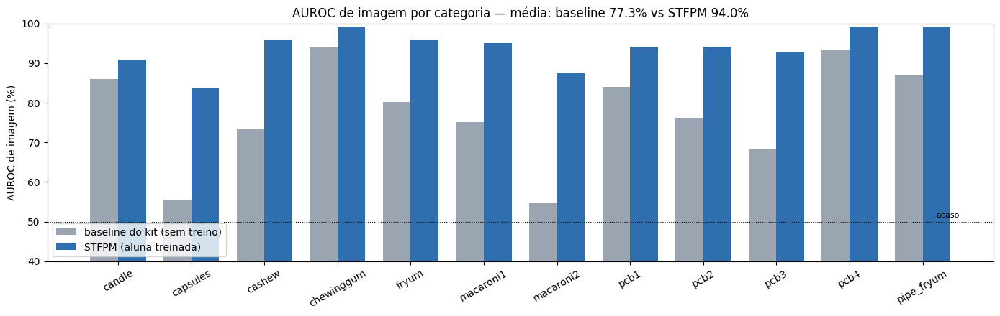

In [17]:
x = np.arange(len(CATS)); w = 0.38
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.bar(x - w/2, tab_base["img_auroc"][:-1], w, label="baseline do kit (sem treino)", color="#9aa5b1")
ax.bar(x + w/2, tab_stfpm["img_auroc"][:-1], w, label="STFPM (aluna treinada)", color="#2f6fb0")
ax.axhline(50, c="k", lw=.8, ls=":"); ax.text(len(CATS) - .5, 51, "acaso", ha="right", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(CATS, rotation=30)
ax.set_ylabel("AUROC de imagem (%)"); ax.set_ylim(40, 100); ax.legend(loc="lower left")
ax.set_title(f"AUROC de imagem por categoria — média: baseline {tab_base['img_auroc'].iloc[-1]:.1f}% "
             f"vs STFPM {tab_stfpm['img_auroc'].iloc[-1]:.1f}%")
plt.tight_layout(); plt.savefig(os.path.join(SAIDA, "comparacao_baseline.png"), dpi=120); plt.show()

### 8.2 Curvas ROC de imagem

A AUROC resume a curva ROC em um único número; aqui está a **curva inteira** (TPR × FPR dos escores de imagem do STFPM) para cada categoria rodada. A categoria **mediana** (AUROC mais próxima da mediana) é destacada em vermelho e, no painel da direita, comparada ao baseline do kit nos mesmos dados de teste. Quanto mais a curva "abraça" o canto superior esquerdo, melhor a separação entre normais e anômalas.


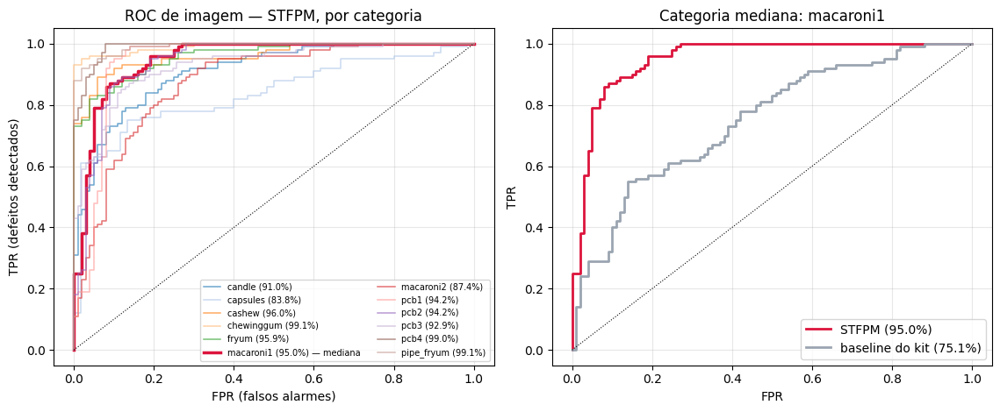

In [18]:
from sklearn.metrics import roc_curve

aurocs = {c: res_stfpm[c]["img_auroc"] for c in CATS}
mediana = min(CATS, key=lambda c: abs(aurocs[c] - np.median(list(aurocs.values()))))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))
cmap = plt.get_cmap("tab20")
for k, cat in enumerate(CATS):
    o = saidas[cat]
    fpr, tpr, _ = roc_curve(o["y"], o["esc"])
    destaque = cat == mediana
    axes[0].plot(fpr, tpr, lw=2.5 if destaque else 1.1,
                 color="crimson" if destaque else cmap(k % 20),
                 alpha=1.0 if destaque else 0.65,
                 label=f"{cat} ({aurocs[cat]:.1f}%)" + (" — mediana" if destaque else ""))
axes[0].plot([0, 1], [0, 1], "k:", lw=0.8)
axes[0].set_xlabel("FPR (falsos alarmes)"); axes[0].set_ylabel("TPR (defeitos detectados)")
axes[0].set_title("ROC de imagem — STFPM, por categoria")
axes[0].legend(fontsize=7, loc="lower right", ncol=2)

o = saidas[mediana]
fpr, tpr, _ = roc_curve(o["y"], o["esc"])
axes[1].plot(fpr, tpr, color="crimson", lw=2, label=f"STFPM ({aurocs[mediana]:.1f}%)")
if "esc_base" in o:   # escores do baseline guardados no laço da Seção 6
    fb, tb, _ = roc_curve(o["y"], o["esc_base"])
    axes[1].plot(fb, tb, color="#9aa5b1", lw=2,
                 label=f"baseline do kit ({res_base[mediana]['img_auroc']:.1f}%)")
axes[1].plot([0, 1], [0, 1], "k:", lw=0.8)
axes[1].set_xlabel("FPR"); axes[1].set_ylabel("TPR")
axes[1].set_title(f"Categoria mediana: {mediana}")
axes[1].legend(loc="lower right")
for a in axes: a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(SAIDA, "curvas_roc.png"), dpi=120); plt.show()


### 8.3 Regra de pontuação (análise, sem retreinar)

Mesmas features da aluna treinada, com três maneiras diferentes de transformar a discrepância em escore e mapa (todas com o σ oficial). **A submissão usa só a regra oficial, escolhida antes do teste.** Esta tabela é uma análise feita depois e **não** serve para escolher a regra, porque escolher pela nota no teste violaria a regra R2. A regra oficial foi escolhida na Seção 6.2 pelo AUROC-proxy; compare: **o ranking das regras no teste concorda com o ranking no proxy?** Se concordar, a validação sintética é um bom guia; se não, é um exemplo da lição do enunciado (representação ≠ regra ≠ métrica).

In [19]:
linhas = []
for nome in REGRAS:
    t = tabela_resultados(res_regras[nome]).iloc[-1]
    linhas.append({"regra": nome, "img AUROC": t["img_auroc"], "px AUROC": t["px_auroc"], "AU-PRO": t["au_pro"]})
display(pd.DataFrame(linhas).round(1))

,regra,img AUROC,px AUROC,AU-PRO
0,produto+max (oficial),94.5,98.6,92.1
1,soma normalizada+max,94.0,98.6,91.3
2,produto+top1%,94.6,98.6,92.1


### 8.4 Custo computacional

In [20]:
tab_custo = pd.DataFrame(custos).T
tab_custo.loc["MÉDIA"] = tab_custo.mean()
print(f"Parâmetros treináveis (aluna): {N_PARAMS / 1e6:.2f} M | GPU: "
      f"{torch.cuda.get_device_name(0) if DEV == 'cuda' else 'CPU'}")
print(f"Tempo total de treino: {tab_custo['treino (s)'][:-1].sum() / 60:.1f} min")
display(tab_custo.round(1))

Parâmetros treináveis (aluna): 2.78 M | GPU: Tesla T4
Tempo total de treino: 33.2 min


,treino (s),inferência (ms/img),melhor época
candle,203.1,10.6,92.0
capsules,123.1,10.2,97.0
cashew,98.4,10.3,99.0
chewinggum,102.4,10.7,93.0
fryum,102.1,10.3,99.0
macaroni1,212.4,10.1,97.0
macaroni2,212.0,10.6,97.0
pcb1,200.6,10.2,99.0
pcb2,212.2,10.1,96.0
pcb3,211.5,10.3,94.0


## 9. Arquivo de submissão

In [21]:
if COMPLETO:
    arq_csv = U.salvar_submissao([tab_stfpm], os.path.join(SAIDA, f"{NOME_ARQUIVO}.csv"))
else:
    arq_csv = None
    print("Modo de teste (categorias parciais): CSV de submissão NÃO gerado.")
    print("Para a entrega, rode com CATS_RODAR = None (todas as 12 categorias).")
S_grad = tab_stfpm["img_auroc"].iloc[-1]
rotulo = "" if COMPLETO else " (PARCIAL — não vale como escore oficial)"
print(f"\nS_grad{rotulo} = {S_grad:.2f} %   (baseline: {tab_base['img_auroc'].iloc[-1]:.2f} %)")
print(f"bônus: px AUROC = {tab_stfpm['px_auroc'].iloc[-1]:.2f} % | AU-PRO = {tab_stfpm['au_pro'].iloc[-1]:.2f} %")
if arq_csv:
    print("CSV salvo em", arq_csv, " -> copie esses números para a tabela do topo do notebook")


dataset categoria  img_auroc  px_auroc  au_pro
   visa     MEDIA      93.96     98.61   91.34

S_grad = 93.96 %   (baseline: 77.29 %)
bônus: px AUROC = 98.61 % | AU-PRO = 91.34 %
CSV salvo em /content/drive/MyDrive/TP1_BCC406/otavio-alves.csv  -> copie esses números para a tabela do topo do notebook


## 10. Análise qualitativa

Para dar nome aos casos (VP/VN/FP/FN), uso um **limiar tirado só da validação**: o percentil 95 dos escores das normais de validação de cada categoria. Ele não entra em nenhuma métrica oficial (que não usa limiar) e serve só para separar os acertos das falhas. Para cada categoria são mostrados:

* **VP**: a anômala com o maior escore (acerto mais confiante);
* **VN**: a normal com o menor escore;
* **FP**: a normal com o **maior** escore (o pior alarme falso);
* **FN**: a anômala com o **menor** escore (o defeito mais "escondido").

Os mapas são exibidos na mesma escala de cor dentro de cada categoria.

melhores: ['pipe_fryum', 'chewinggum', 'pcb4'] | piores: ['capsules', 'macaroni2', 'candle']


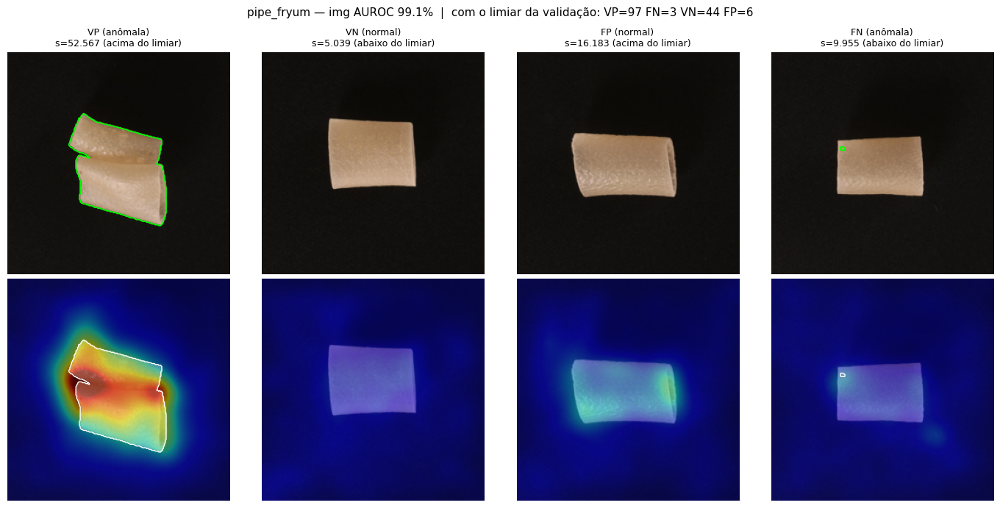

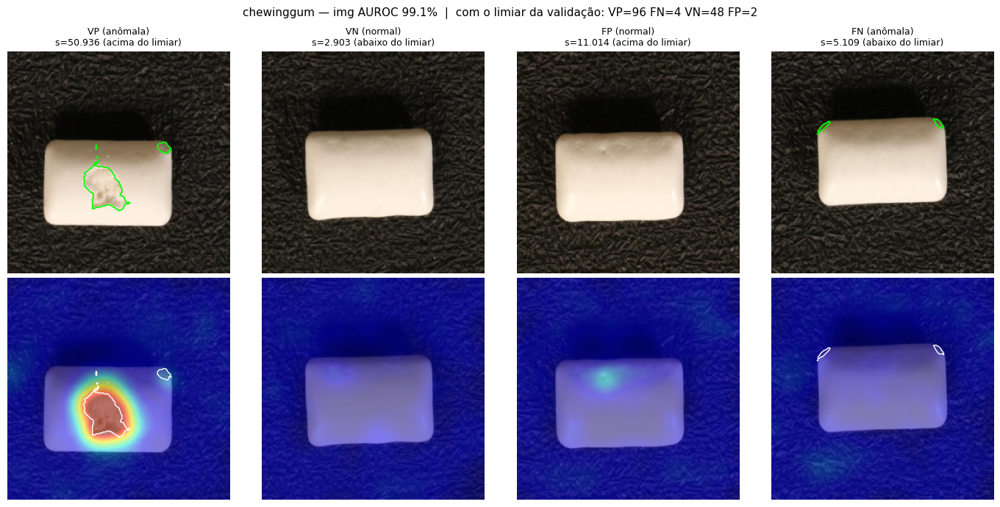

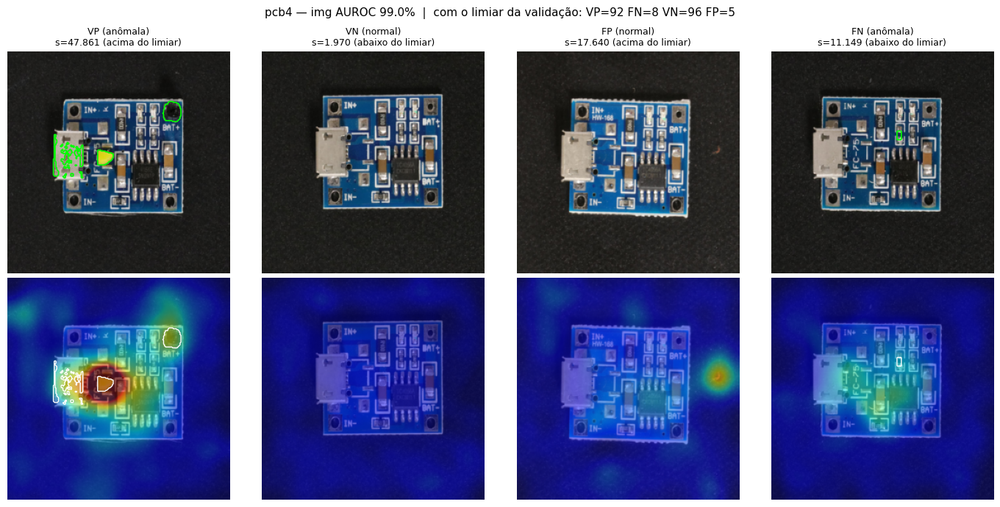

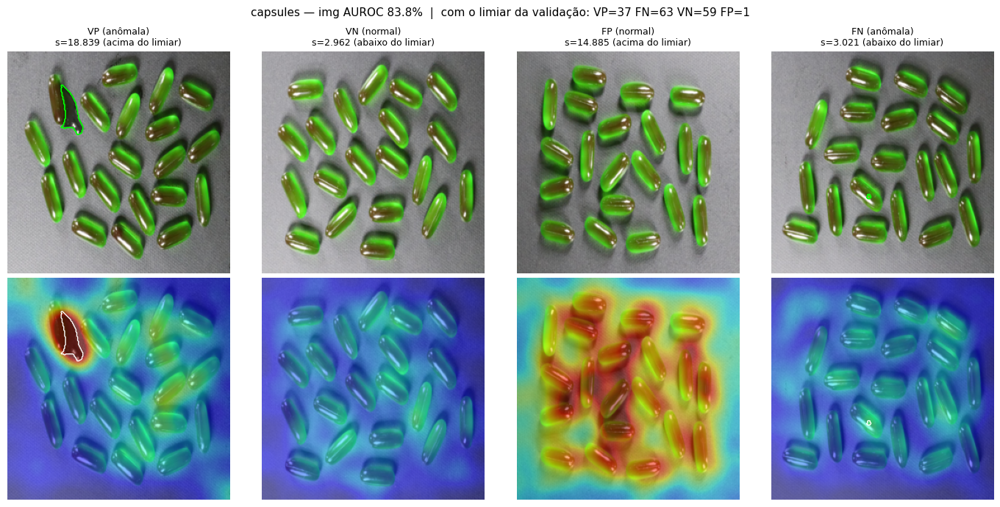

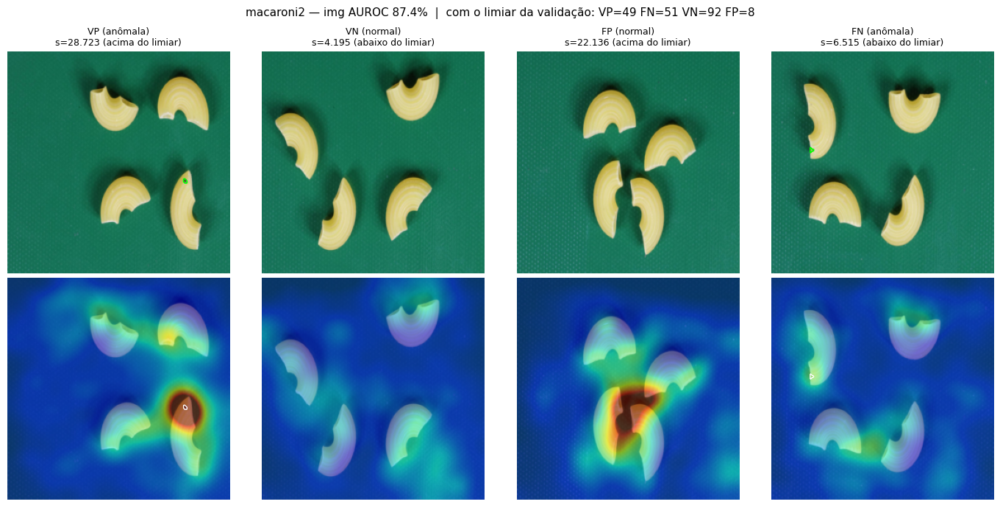

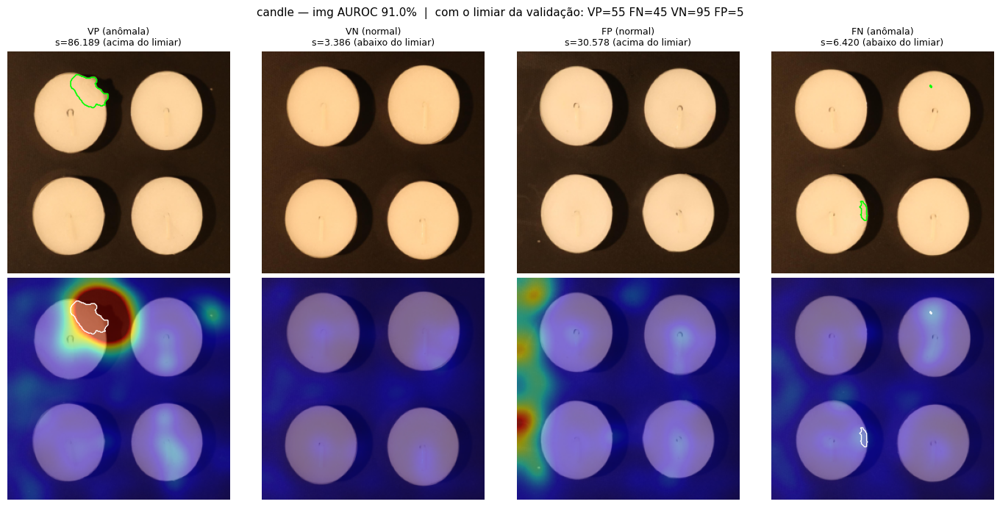

In [22]:
ordem = tab_stfpm.iloc[:-1].sort_values("img_auroc")
piores, melhores = list(ordem["categoria"][:3]), list(ordem["categoria"][-3:][::-1])
print("melhores:", melhores, "| piores:", piores)


def mostrar_casos(cat):
    te, o = carregar_split(cat, "test"), saidas[cat]
    esc, y, mapa, tau = o["esc"], o["y"], o["mapa"].float().numpy(), o["limiar"]
    idx_n, idx_a = np.where(y == 0)[0], np.where(y == 1)[0]
    casos = [("VP", idx_a[esc[idx_a].argmax()]), ("VN", idx_n[esc[idx_n].argmin()]),
             ("FP", idx_n[esc[idx_n].argmax()]), ("FN", idx_a[esc[idx_a].argmin()])]
    vmin, vmax = np.percentile(mapa, 1), np.percentile(mapa, 99.9)
    pred = esc > tau
    vp, fp = int((pred & (y == 1)).sum()), int((pred & (y == 0)).sum())
    fn, vn = int((~pred & (y == 1)).sum()), int((~pred & (y == 0)).sum())
    fig, ax = plt.subplots(2, 4, figsize=(14, 7))
    for j, (nome, i) in enumerate(casos):
        img = te["X"][i].permute(1, 2, 0).numpy()
        ax[0, j].imshow(img)
        if y[i] == 1:
            ax[0, j].contour(te["M"][i].numpy(), levels=[0.5], colors="lime", linewidths=1.2)
        rot = "anômala" if y[i] == 1 else "normal"
        decisao = "acima" if esc[i] > tau else "abaixo"
        ax[0, j].set_title(f"{nome} ({rot})\ns={esc[i]:.3f} ({decisao} do limiar)", fontsize=9)
        ax[1, j].imshow(img); ax[1, j].imshow(mapa[i], cmap="jet", alpha=.5, vmin=vmin, vmax=vmax)
        if y[i] == 1:
            ax[1, j].contour(te["M"][i].numpy(), levels=[0.5], colors="white", linewidths=1)
    for a in ax.ravel(): a.axis("off")
    plt.suptitle(f"{cat} — img AUROC {res_stfpm[cat]['img_auroc']:.1f}%  |  com o limiar da validação: "
                 f"VP={vp} FN={fn} VN={vn} FP={fp}", fontsize=11)
    plt.tight_layout(); plt.show()


for cat in dict.fromkeys(melhores + piores):   # sem repetir em modo de teste
    mostrar_casos(cat)

**Discussão dos casos.**

* **Melhores categorias** (`pipe_fryum` 99,1%, `chewinggum` 99,1%, `pcb4` 99,0%): os mapas acendem sobre o contorno real do defeito. Não por acaso, `chewinggum` e `pcb4` têm os **maiores defeitos** do dataset (0,50% e 0,87% de área mediana — Seção 3): defeitos de textura/cor locais e visíveis são o caso fácil para professor-aluno, porque a aluna nunca viu aquele padrão de feature e a discrepância dispara.
* **Piores categorias** (`capsules` 83,8%, `macaroni2` 87,4%, `candle` 91,0%): justamente as de **múltiplas instâncias**, que combinam defeitos minúsculos (0,05–0,15% de área mediana) com **anomalias lógicas** (peça a mais, fora do lugar, quebra sutil) que localmente parecem normais — difíceis para qualquer método de patches locais. Nos FP, o mapa acende em peças em poses pouco frequentes no treino; nos FN, o defeito é pequeno demais para a resolução efetiva dos mapas (64×64 na escala mais fina).
* **Comparação com o baseline (Figura 5 do enunciado):** o STFPM resolveu em grande parte os falsos alarmes do baseline nessas mesmas categorias (`capsules` 55,6 → 83,8; `macaroni2` 54,6 → 87,4). Faz sentido: a aluna aprende a imitar a professora **em qualquer posição**, então o deslocamento natural das peças deixa de ser confundido com defeito — exatamente a falha da média por posição do baseline.


### 10.1 Mapas de anomalia (bônus de localização)

Uma imagem anômala de teste por categoria, sorteada com semente fixa: a imagem com a máscara real e, abaixo, o mapa do STFPM.

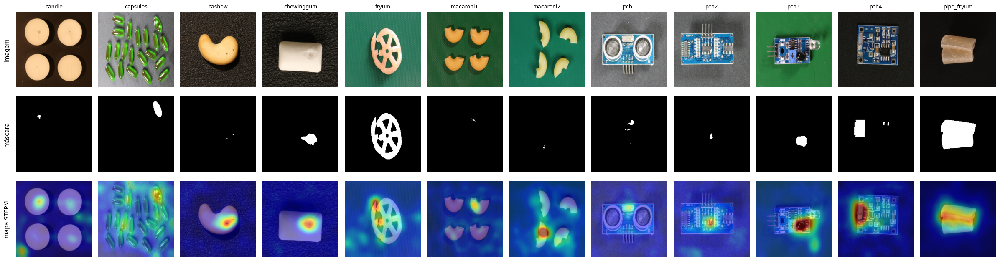

 categoria  px_auroc  au_pro
    candle      98.9    95.2
  capsules      98.5    87.5
    cashew      98.3    92.7
chewinggum      98.5    82.9
     fryum      95.5    84.3
 macaroni1      99.5    96.6
 macaroni2      99.2    94.7
      pcb1      99.7    96.1
      pcb2      98.6    90.6
      pcb3      98.9    90.4
      pcb4      98.7    91.3
pipe_fryum      99.1    93.7
     MEDIA      98.6    91.3


In [23]:
rng = np.random.default_rng(SEMENTE)
fig, ax = plt.subplots(3, len(CATS), figsize=(2 * len(CATS), 6.5), squeeze=False)
for j, cat in enumerate(CATS):
    te, o = carregar_split(cat, "test"), saidas[cat]
    mapa = o["mapa"].float().numpy()
    i = rng.choice(np.where(o["y"] == 1)[0])
    img = te["X"][i].permute(1, 2, 0).numpy()
    ax[0, j].imshow(img); ax[0, j].set_title(cat, fontsize=9)
    ax[1, j].imshow(te["M"][i].numpy(), cmap="gray")
    ax[2, j].imshow(img); ax[2, j].imshow(mapa[i], cmap="jet", alpha=.5,
                                          vmin=np.percentile(mapa, 1), vmax=np.percentile(mapa, 99.9))
for a in ax.ravel(): a.axis("off")
ax[0, 0].text(-20, 128, "imagem", rotation=90, va="center", ha="right")
ax[1, 0].text(-20, 128, "máscara", rotation=90, va="center", ha="right")
ax[2, 0].text(-20, 128, "mapa STFPM", rotation=90, va="center", ha="right")
plt.tight_layout(); plt.savefig(os.path.join(SAIDA, "mapas_anomalia.png"), dpi=110); plt.show()

print(tab_stfpm[["categoria", "px_auroc", "au_pro"]].round(1).to_string(index=False))

## 11. Discussão e conclusão

1. **Resultado geral.** O STFPM obteve **S_grad = 93,96%** contra 77,29% do baseline (**+16,7 p.p.**), superando o baseline em todas as 12 categorias. Na localização (bônus), AUROC de pixel = **98,61%** e AU-PRO@30% = **91,34%** (baseline: 95,5% e 74,2%).
2. **Validação sintética.** A Seção 6.2 escolheu **augmentation = não, regra = soma normalizada+max e σ = 8** pelo AUROC-proxy (93,64%), sem tocar no teste. As três melhores combinações do proxy foram todas **sem** augmentation: os flips pioraram o proxy de forma consistente, indício de que tornar a aluna invariante a espelhamentos dilui a sua especialização na aparência normal de cada categoria (a professora, pré-treinada, já é razoavelmente invariante; a vantagem da aluna está em ser específica). No teste (Seção 8.3), a regra escolhida ficou 0,6 p.p. abaixo da melhor pós-hoc em img AUROC (94,0% vs 94,6%) — o proxy é um guia bom, mas não perfeito, e as três regras ficaram dentro de uma faixa estreita.
3. **Onde o treino ajuda.** A ablação com a aluna **sem treino** (pesos aleatórios) cai para **52,1%** de img AUROC — praticamente o acaso. Todo o desempenho vem da retropropagação nas imagens normais, não da professora pré-treinada sozinha.
4. **Por grupo de categoria.** Objetos únicos: 95,9–99,1% (o melhor grupo). PCBs: 92,9–99,0%, consistentes. Múltiplas instâncias: o gargalo (83,8–95,0%), pela combinação de defeitos minúsculos e anomalias lógicas discutida nas Seções 3 e 10 — ainda assim, é o grupo com o maior ganho sobre o baseline (até +32,8 p.p. em `macaroni2`).
5. **Regra de pontuação.** Na Seção 8.3, a conclusão sobre "qual regra é melhor" **muda com a métrica**: a detecção prefere produto+top1% (94,6% img AUROC), a localização prefere produto+max (AU-PRO 92,1% vs 91,3% da soma) e o AUROC de pixel empata (98,6% nas três). É a lição do enunciado na prática: *representação ≠ regra de pontuação ≠ métrica*.
6. **Limitações e trabalhos futuros.** Resolução de 256 px para defeitos que ocupam ≤ 0,1% da imagem; um modelo por categoria (não testei um modelo único); uma única semente; anomalias lógicas fora do alcance de patches locais; o CutPaste cobre só defeitos estruturais, o que pode enviesar o proxy (p. ex., contra o augmentation). Melhorias possíveis: resolução maior, Reverse Distillation (Deng & Li, 2022), um backbone maior (Wide-ResNet-50) e uma cabeça de segmentação discriminativa treinada com anomalias sintéticas (estilo DRAEM) sobre os mapas do STFPM.

**Conformidade com as regras:** só CNNs (ResNet-18); pesos pré-treinados só do ImageNet; uma aluna treinada do zero com retropropagação; treino, escolha de época, estatísticas de normalização e limiar usando só `train`/`val` (imagens normais); augmentation, σ e regra de pontuação escolhidos por **validação sintética** (CutPaste sobre as normais de `val` — permitido e incentivado pelas regras R1/R3), sem tocar no teste; teste usado uma vez, na avaliação final; métricas calculadas com `tp1_utils` sem modificação; nenhuma biblioteca de detecção pronta.

### Referências
* G. Wang et al. *Student-Teacher Feature Pyramid Matching for Anomaly Detection.* BMVC 2021 (método implementado).
* Y. Zou et al. *SPot-the-Difference Self-Supervised Pre-training for Anomaly Detection and Segmentation.* ECCV 2022 (dataset VisA).
* P. Bergmann et al. *Uninformed Students.* CVPR 2020 (métrica PRO; ideia professor-aluno).
* C.-L. Li et al. *CutPaste: Self-Supervised Learning for Anomaly Detection and Localization.* CVPR 2021 (anomalias sintéticas da validação).
* K. He et al. *Deep Residual Learning for Image Recognition.* CVPR 2016 (ResNet).
* Kit de apoio da disciplina (`tp1_utils.py`, `exemplo_baseline.ipynb`), Prof. Eduardo Luz. O baseline da Seção 4 reproduz o código do kit.